# Figure 5g. Astrocytic program and glycoprotein network

Connected STRING network for astrocyte trans-eProgram 80 and colocalized glycoproteins at the GDA locus. This display retains 61 connected nodes and 70 within-input links; GDA and disconnected nodes are omitted from this view. Red links have physical-network support, which does not by itself demonstrate direct binding. Blue-grey links indicate functional association only.

Input: `data/Figure_5g_ast80_glycoprotein_PPI.rds` (plot-ready node positions and links; STRING v12.5).

In [1]:
suppressPackageStartupMessages(library(ggplot2))
suppressPackageStartupMessages(library(ggrepel))
d <- readRDS("data/Figure_5g_ast80_glycoprotein_PPI.rds")
stopifnot(nrow(d$nodes) == 61L, nrow(d$edges) == 70L,
          sum(d$nodes$group == "Glycoprotein") == 8L,
          all(c(d$edges$gene_id_a, d$edges$gene_id_b) %in% d$nodes$gene_id))
d$nodes$group <- factor(d$nodes$group,
  levels = c("Ast. trans-eProgram", "Ast. co-culture", "Glycoprotein"))
d$edges$link_type <- factor(d$edges$link_type,
  levels = c("Physical-proximity link", "Functional association only"))
d$nodes$point_size <- ifelse(d$nodes$group == "Glycoprotein", 3.2,
  ifelse(d$nodes$group == "Ast. co-culture", 2.8, 2.4))
options(repr.plot.width = 12, repr.plot.height = 8.4)

Warning message:
"package 'ggplot2' was built under R version 4.4.3"


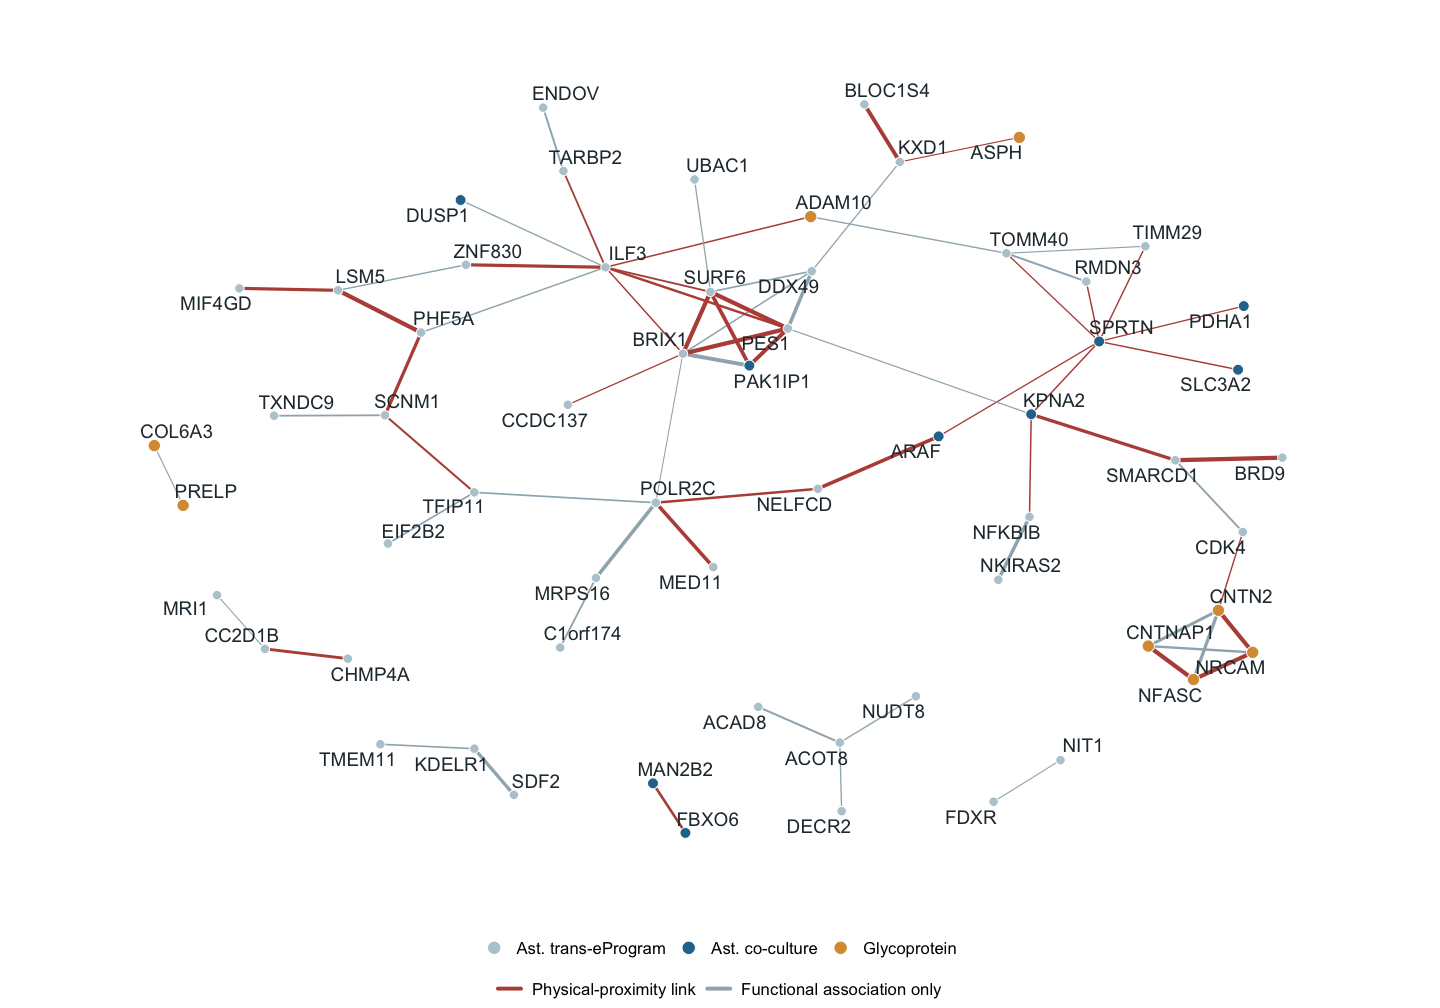

In [2]:
p <- ggplot() +
  geom_segment(data = d$edges,
               aes(x = x, y = y, xend = xend, yend = yend,
                   linewidth = score, color = link_type),
               lineend = "round") +
  geom_point(data = d$nodes,
             aes(x = x, y = y, fill = group, size = point_size),
             shape = 21, color = "white", stroke = 0.4) +
  geom_text_repel(data = d$nodes,
                  aes(x = x, y = y, label = symbol),
                  size = 4.0, color = "#26353C", seed = 20261003,
                  max.overlaps = Inf, max.time = 30, max.iter = 50000,
                  force = 2, force_pull = 0.15,
                  xlim = c(0.01, 0.99), ylim = c(0.01, 0.99),
                  box.padding = 0.25, point.padding = 0.18,
                  segment.color = NA, show.legend = FALSE) +
  scale_color_manual(values = c("Physical-proximity link" = "#B84F45",
                                "Functional association only" = "#9FB2BC"),
                     name = NULL, guide = guide_legend(order = 2,
                       override.aes = list(linewidth = 1.1))) +
  scale_fill_manual(values = c("Ast. trans-eProgram" = "#B7CBD4",
                               "Ast. co-culture" = "#28749A",
                               "Glycoprotein" = "#D99A40"),
                    name = NULL, guide = guide_legend(order = 1,
                      override.aes = list(size = 3.5, shape = 21))) +
  scale_size_identity() +
  scale_linewidth_continuous(range = c(0.3, 1.2), guide = "none") +
  coord_cartesian(xlim = c(0, 1), ylim = c(0, 1),
                  expand = FALSE, clip = "off") +
  theme_void(base_size = 10) +
  theme(legend.position = "bottom", legend.box = "vertical",
        legend.text = element_text(size = 10),
        plot.margin = margin(8, 10, 3, 8))
print(p)